<h1><center>Multi-layer Perceptron</center></h1>

In this mini-project, we will implement a simple one hidden layer neural network from scratch.
Even if you will use deep learning libraries like Pytorch or Tensorflow later, implementing a network from scratch at least once is an extremely useful exercise, essential for designing and optimizing your own models effectively.


In [1]:
!pip install numpy
!pip install sklearn

# Imports of useful packages
import matplotlib # For the plots
import matplotlib.pyplot as plt 
import numpy as np # To perform operations on matrices efficiently


# We will use the sklearn library to compare our neural network to that 
# of a simpler approach like logistic regression

import sklearn 
import sklearn.datasets
import sklearn.linear_model

from math import exp,log

# To display plots inline and adjust the display

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (10.0, 8.0)

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SK

# Generating a dataset

Let's start by generating a dataset that we can play with. The scikit-learn machine learning library has a few useful data generators, saving us the trouble of writing the code ourselves. We will use the make_moons function, which creates a two-class dataset of two-dimensional examples in the shape of two half-moons: each of the half-moons corresponds to a class.

In [2]:
np.random.seed(1)
X, y = sklearn.datasets.make_moons(n_samples=300, noise=0.20)  # We create a dataset with 300 elements


 <font color='red'><b>Question 1.</b></font> Show the coordinates and labels of the first two elements of the dataset.



In [3]:
# You can use f-string as proposed below (https://www.geeksforgeeks.org/formatted-string-literals-f-strings-python/)
print(f"The first coordinate point {X[0]} has a label {y[0]}")
print(f"The second coordinate point {X[1]} has a label {y[1]}")

The first coordinate point [ 0.21073485 -0.0159868 ] has a label 1
The second coordinate point [-0.82910413  0.65187765] has a label 0


We can display this dataset easily using Matplotlib using colors to make the labels appear $y$ : 

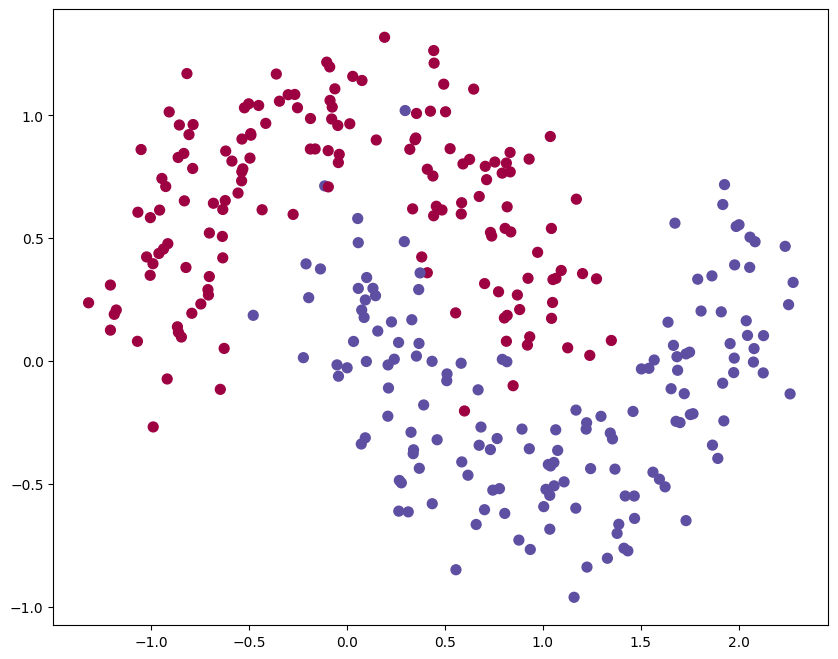

In [4]:
plt.scatter(X[:,0], X[:,1], s=50, c=y+1, cmap=plt.cm.Spectral)
plt.show()

The dataset we generated has two classes, represented by red and blue dots.

Our goal is to train a classifier that predicts the correct class from point coordinates $x_1$ et $x_2$. 

# Find the best line manually

In this part we will try to find the best line that separates our cloud of points manually.

<font color='red'><b>Question 2</b></font>  Creates a function that returns 1 if a coordinate point $(x_1,x_2$) is below the line with slope $a$ and the bias $b$.

In [5]:
def pred_linear(a: float, b: float, x1: float, x2: float):
    return 1 if x2 < a * x1 + b else 0

It is important to be able to evaluate the performance of our approaches using metrics. Here, we will choose the accuracy which is simply the number of well-classified elements divided by the total number of elements. To learn more about classification metrics like precision, recall and their link with accuracy, you can consult the following excellent Wikipedia (if you plan to do Machine Learning later, the notion of precision/recall is a classic) https://en.wikipedia.org/wiki/Precision_and_recall

<font color='red'><b>Question 3.</b></font> Complete the following accuracy function. (1 Python line with the comprehension of a list)

In [6]:
def accuracy(y_true, y_pred):
    """
    Args:
        y_true (list[int]): A list of integers having values in {0,1} that contain the class labels
        y_pred (list[int]): A list of integers having values in {0,1} that contain the predictions of the model

    Returns:
        float: The Accuracy of the model
    
    Example:
    >>> accuracy([0,0,1], [0,1,1])
    0.666...
    """
    return sum([1 for t, p in zip(y_true, y_pred) if t == p]) / len(y_true)

In [7]:
#### display function
def plot_decision_boundary(pred_func):
    """
    Shows the decision boundaries of a binary prediction function.
    """
    # Set grid dimensions and give some margin for display
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    h = 0.01
    # Generate the grid of points with a distance of h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Drawing the decision boundary
    Z = pred_func(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Show contour and training points
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Spectral)

<font color='red'><b>Question 4.</b></font>  Play by hand with parameters $a$ and $b$ to obtain several linear decision boundaries and try to obtain at least 80% accuracy.



le score obtenu est de:  0.8633333333333333


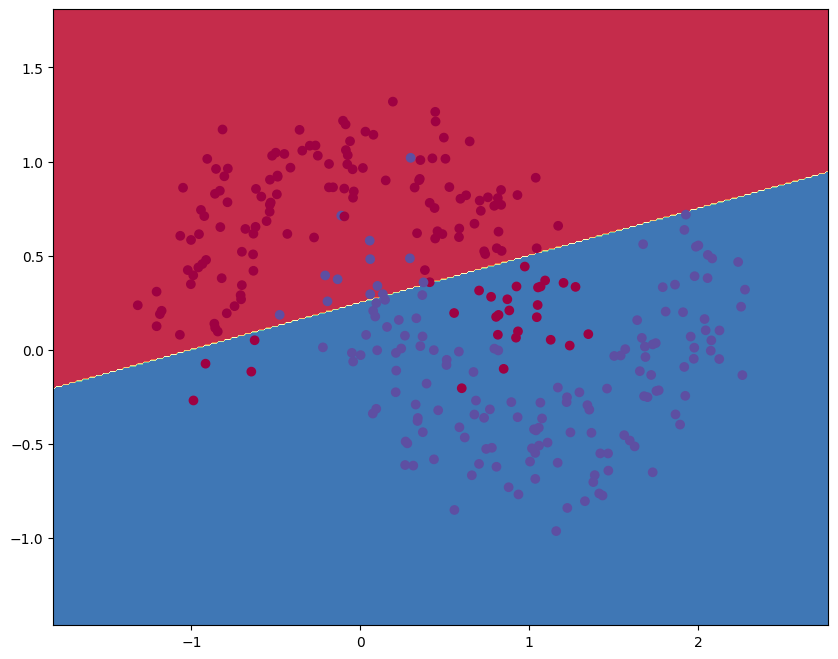

In [8]:
a = 0.25
b = 0.25
def prediction(A, a, b, func):
    return np.array([func(a=a, b=b, x1=x[0], x2=x[1]) for x in A])
plot_decision_boundary(lambda x: prediction(x, a, b, pred_linear))
print('le score obtenu est de: ', accuracy(y, prediction(X, a, b, pred_linear)))

# Logistic Regression

Scikit-learn has models such as logistic regression which can find the optimal parameters a and b:

In [9]:
classifier = sklearn.linear_model.LogisticRegressionCV()

 <font color='red'><b>Question 5.</b></font> Train this logistic regression model on the dataset (X,y). You can use the Scikit-learn documentation to see how to train a model on data: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [10]:
classifier.fit(X, y)

/home/ensimag/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/ensimag/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add a L2 penalty term (used by default);- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy ` is used.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass 

Once the model is trained, it can be used to predict and draw the decision boundary:

le score obtenu est de:  0.8566666666666667


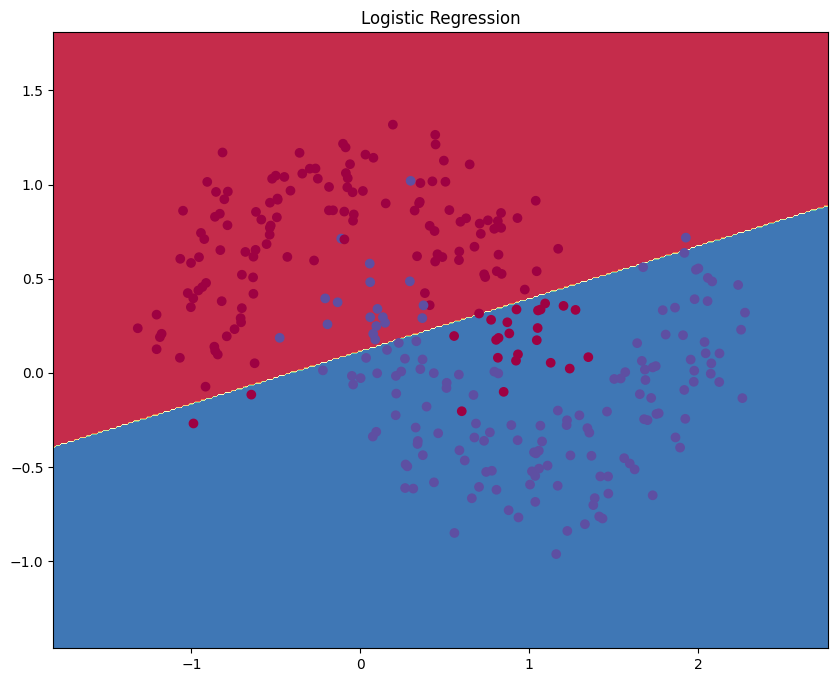

In [11]:
plot_decision_boundary(lambda x: classifier.predict(x))
plt.title("Logistic Regression")
print('le score obtenu est de: ', accuracy(y, classifier.predict(X)))

 <font color='red'><b>Question 6.</b></font> What do you observe? Was such a result predictable? What can we do to improve our predictions?

**Answer to Question 6.**

The decision boundary is a straight line, which gives about 86% accuracy. The errors are where the two moons overlap — no line can separate them perfectly.

It was predictable: logistic regression is a linear model, so its boundary is always a hyperplane. The moons dataset is not linearly separable so we can't do better with this approach.

To improve: we could add non-linear features (e.g. $x_1^2$, $x_2^2$), use a kernel SVM, or use a neural network with a hidden layer — which is exactly what we do next.

<font color='red'><b>Bonus Question.</b></font> Find the coefficients $a, b$ obtained by Scikit-learn logistic regression.

In [12]:
w1, w2 = classifier.coef_[0]
c = classifier.intercept_[0]
print("coef_ =", classifier.coef_, " intercept_ =", classifier.intercept_)

# boundary: w1*x1 + w2*x2 + c = 0  =>  x2 = a*x1 + b
a_lr = -w1 / w2
b_lr = -c / w2
print(f"a = {a_lr:.4f}, b = {b_lr:.4f}")
print("accuracy with pred_linear:", accuracy(y, prediction(X, a_lr, b_lr, pred_linear)))
print("accuracy sklearn:", accuracy(y, classifier.predict(X)))

coef_ = [[ 1.28640251 -4.60570681]]  intercept_ = [0.51730351]
a = 0.2793, b = 0.1123
accuracy with pred_linear: 0.8566666666666667
accuracy sklearn: 0.8566666666666667


# Neural Networks

You will now create a neural network to solve the previous problem.

In [13]:
# We will reuse the same datasets as previously, be careful X and y will be global variables for the rest 
# (to be avoided in general, but simplifies the notations for this mini porject)
np.random.seed(1)
X, y = sklearn.datasets.make_moons(300, noise=0.20)

 <font color='red'><b> Question 7</b></font> Complete the following variables and functions to code a **two-layer** neural network (1 hidden layer). The hidden layer will currently have **10 neurons** and we will use a learning rate of 3e-2.


In [14]:
# number of examples in the training set

N = len(X)

# dimension of the input
d_input = X.shape[1]

# dimension of the output (one output per class: the label is one-hot encoded)
d_output = 2

# dimension of the hidden layer i.e. number of neurons in the hidden layer
d_hidden = 10



# learning rate for the gradient descente algorithm
epsilon = 3e-2

 <font color='red'><b> Question 8</b></font> Complete the following function to generate the parameters of our neural network. For this you will use the random library to generate parameters in the interval [-0.5, 0.5] using the random.random() function.

In [15]:
import random

In [16]:
def init_model(d_input: int, d_hidden: int, d_output: int):
    """
    Args:
        d_input (int): dimension of the input
        d_hidden (int): dimension of the hidden layer
        d_output (int): dimension of the output

    Returns:
        dict: Dictionary containing 4 keys, the weights/biases (W1,b1) and (W2,b2) of the neural network.
        Each of these weights and biases are lists or list of lists of float.
    """
    # Initialization of random parameters
    random.seed(0)
    # First layer of size d_input x d_hidden
    W1 = [[random.random() - 0.5 for _ in range(d_hidden)] for _ in range(d_input)]
    # Bias of the first layer vector of size d_hidden
    b1 = [random.random() - 0.5 for _ in range(d_hidden)]
    # Second layer of size d_hidden x d_output
    W2 = [[random.random() - 0.5 for _ in range(d_output)] for _ in range(d_hidden)]
    # The bias of the second layer
    b2 = [random.random() - 0.5 for _ in range(d_output)]
    # The model returned at the end is a dictionary of weights and biases
    model = { 'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
    return model

<font color='red'><b> Question 9</b></font> Implement the following mathematical functions which may be useful later. All vectors $v_1,v_2$ are python lists and the matrices $X$ and $W$ are lists of lists.

In [17]:
# dot product between two vectors
def dot_product(v1, v2):
    return sum(a * b for a, b in zip(v1, v2))

# Add two vectors
def add_bias(v1, v2):
    return [a + b for a, b in zip(v1, v2)]

# Get the columns number "index" of W
def get_columns(W, index):
    return [row[index] for row in W]

# Transpose a matrix
def transpose(W):
    return [get_columns(W, j) for j in range(len(W[0]))]

# Multiplication between two matrices()
def matrix_multiplication(X, W):
    W_T = transpose(W)
    return [[dot_product(row, col) for col in W_T] for row in X]


 <font color='red'><b> Question 10</b></font> Complete the forward_layer function by doing the following:
 $$ X \times W + b $$
 In which X represents the input, W the weights and and b the biases.
 Complete the sigmoid and feed_forward function.

In [18]:
def forward_layer(X, W, b):
    return [add_bias(row, b) for row in matrix_multiplication(X, W)]

In [19]:
def sigmoid(x):
    """"
    Args:
        x (float): input
    returns:
        float : sigmoid(x)
    
    """
    if x >= 0:
        return 1.0 / (1.0 + exp(-x))
    e = exp(x)
    return e / (1.0 + e)

In [20]:
def forward_function(X,W1,b1,W2,b2):     
    z1 = forward_layer(X, W1, b1)  # Output of the first layer
    a1 = [[sigmoid(v) for v in row] for row in z1] # Sigmoid activation of the first layer
    z2 = forward_layer(a1, W2, b2)  # Output of the second layer
    exp_scores = [[exp(v - max(row)) for v in row] for row in z2]# Compute exp(z2)
    probs = [[v / sum(row) for v in row] for row in exp_scores] #Apply softmax activation function on z2
    return probs
       

In [21]:
# Test your result:
np.random.seed(1)
model_test = init_model(4,3,2)
X_debug = [[random.random() for i in range(4)]] # Test with an example in dimension 2
forward_function(X_debug, model_test['W1'], model_test['b1'], model_test['W2'], model_test['b2'])

[[0.47916272248062897, 0.520837277519371]]

You are supposed to find: [[0.48, 0.52]] (if you used the random.random function to initialize the weights)

 <font color='red'><b> Question 11</b></font> We recall the feed forward equations (everything is in matrix form, so $X\in\mathbb{R}^{N\times d_{input}}$,$W_1\in\mathbb{R}^{d_{input }\times d_{hidden}}$, etc). Complete the back propagation equations and complete the sigmoid function, forward function and train_model. Gradient descent on W1 is provided to you.
Reminder on backprop : https://towardsdatascience.com/backpropagation-the-natural-proof-946c5abf63b1

$$
\begin{aligned}
z_1 & = XW_1 + b_1  \\ 
a_1 & = sigmoid(z_1)=\frac{1}{1+\exp(-z_1)} \\
z_2 & = a_1W_2 + b_2 \\
a_2 & = \hat{y} = \mathrm{softmax}(z_2)\\
L(y,\hat{y}) & = - \frac{1}{N} \sum_{n \in N} \sum_{i \in C} y_{n,i} \log\hat{y}_{n,i}
\end{aligned}
$$


Back propagation (with $Y\in\{0,1\}^{N\times C}$ the one-hot encoding of the labels, $\odot$ the element-wise product):
$$
\begin{aligned}
\delta_2 &= \hat{y} - Y \\
\delta_1 &= (\delta_2 W_2^\top) \odot a_1 \odot (1-a_1) \\
\frac{\partial{L}}{\partial{W_2}} &= a_1^\top \delta_2 \\
\frac{\partial{L}}{\partial{b_2}} &= \sum_{n=1}^{N} \delta_2[n,:] \\
\frac{\partial{L}}{\partial{W_1}} &= X^\top \delta_1 \\
\frac{\partial{L}}{\partial{b_1}} &= \sum_{n=1}^{N} \delta_1[n,:]
\end{aligned}
$$

**Note on the $1/N$ factor.** The gradients above are for the sum of per-example losses (not the mean), which is why the learning rates $3\cdot10^{-2}$ and $10^{-3}$ work directly. The printed loss is still the mean.

In [22]:
def train_model(model, nn_hdim, num_epochs=1, print_loss=False):

    W1 = model['W1']
    b1 = model['b1']
    W2 = model['W2']
    b2 = model['b2']

    X_list = X.tolist() if hasattr(X, 'tolist') else X
    labels = [int(v) for v in y]

    # Gradient descent. For each batch...
    for i in range(0, num_epochs):
        
        # Forward propagation 
        z1 = forward_layer(X_list, W1, b1)  # Output of the first layer
        a1 = [[sigmoid(v) for v in row] for row in z1] # Sigmoid activation of the first layer
        probs = forward_function(X_list, W1, b1, W2, b2)
        # Estimate the loss (c)
        correct_logprobs = [-log(max(probs[n][labels[n]], 1e-300)) for n in range(N)] # Calculation of cross entropy for each example
        data_loss = 1./N * sum(correct_logprobs) # Loss totale
        
        
        # Backpropagation
        delta2 = [[p - (1.0 if k == labels[n] else 0.0) for k, p in enumerate(row)] for n, row in enumerate(probs)]
        dW2 = matrix_multiplication(transpose(a1), delta2)
        db2 = [sum(col) for col in transpose(delta2)]
        back = matrix_multiplication(delta2, transpose(W2))
        delta1 = [[g * a * (1 - a) for g, a in zip(g_row, a_row)] for g_row, a_row in zip(back, a1)]
        dW1 = matrix_multiplication(transpose(X_list), delta1)
        db1 = [sum(col) for col in transpose(delta1)]
        
        # Gradient descente
        W1 =[[w - epsilon * d for d, w in zip(dW1_row, W1_row)]for dW1_row, W1_row in zip(dW1, W1)]
        b1 = [b - epsilon * d for b, d in zip(b1, db1)]
        W2 = [[w - epsilon * d for d, w in zip(dW2_row, W2_row)] for dW2_row, W2_row in zip(dW2, W2)]
        b2 = [b - epsilon * d for b, d in zip(b2, db2)]
        # Updating weights and biases
        model = { 'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
        
        # Loss display
        if print_loss and i % 50 == 0:
          print("Loss at epoch %i: %f" %(i, data_loss))
      
    return model

We will need a prediction function that uses our trained model to return predictions. Unlike the model outputs which are floats in [0,1] for each class, the model prediction is 1 on the class whose score is maximum and 0 elsewhere. We use numpy's argmax function to do this automatically.

<font color='red'><b> Question 12</b></font> Complete the function predict() :

In [23]:
def predict(model, x):
    W1, b1, W2, b2 = model['W1'], model['b1'], model['W2'], model['b2']
    x = x.tolist() if hasattr(x, 'tolist') else x
    # Forward propagation, like before
    z1 = forward_layer(x, W1, b1)
    a1 = [[sigmoid(v) for v in row] for row in z1]
    z2 = forward_layer(a1, W2, b2)
    exp_scores = [[exp(v - max(row)) for v in row] for row in z2]
    probs = [[v / sum(row) for v in row] for row in exp_scores]
    return np.argmax(probs, axis=1)

<font color='red'><b> Question 13</b></font> Train the model for different number of epochs and comment on your results.

In [24]:
model = init_model(d_input,d_hidden,d_output)
model = train_model(model,d_hidden, num_epochs=200, print_loss=True)
print("The final accuracy obtained is :", accuracy(y, predict(model, X)))


Loss at epoch 0: 0.732492
Loss at epoch 50: 0.331724
Loss at epoch 100: 0.274587
Loss at epoch 150: 0.249642
The final accuracy obtained is : 0.9633333333333334


Text(0.5, 1.0, 'Decision Boundary for hidden layer size 10')

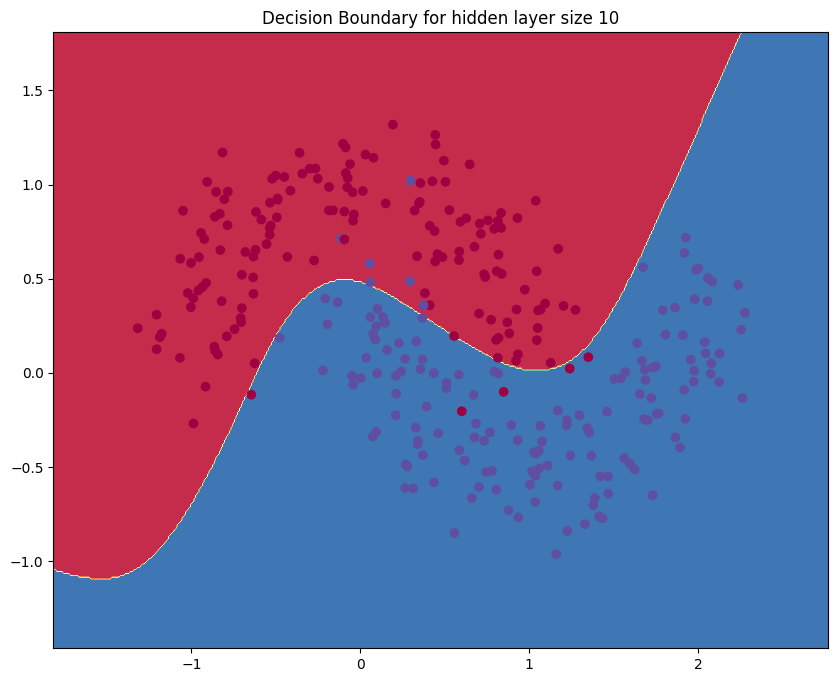

In [25]:
# Plot the decision boundary
plot_decision_boundary(lambda x: predict(model, x))
plt.title("Decision Boundary for hidden layer size 10")

   10 epochs -> accuracy 0.5000
   50 epochs -> accuracy 0.8033
  200 epochs -> accuracy 0.9633
 1000 epochs -> accuracy 0.9700


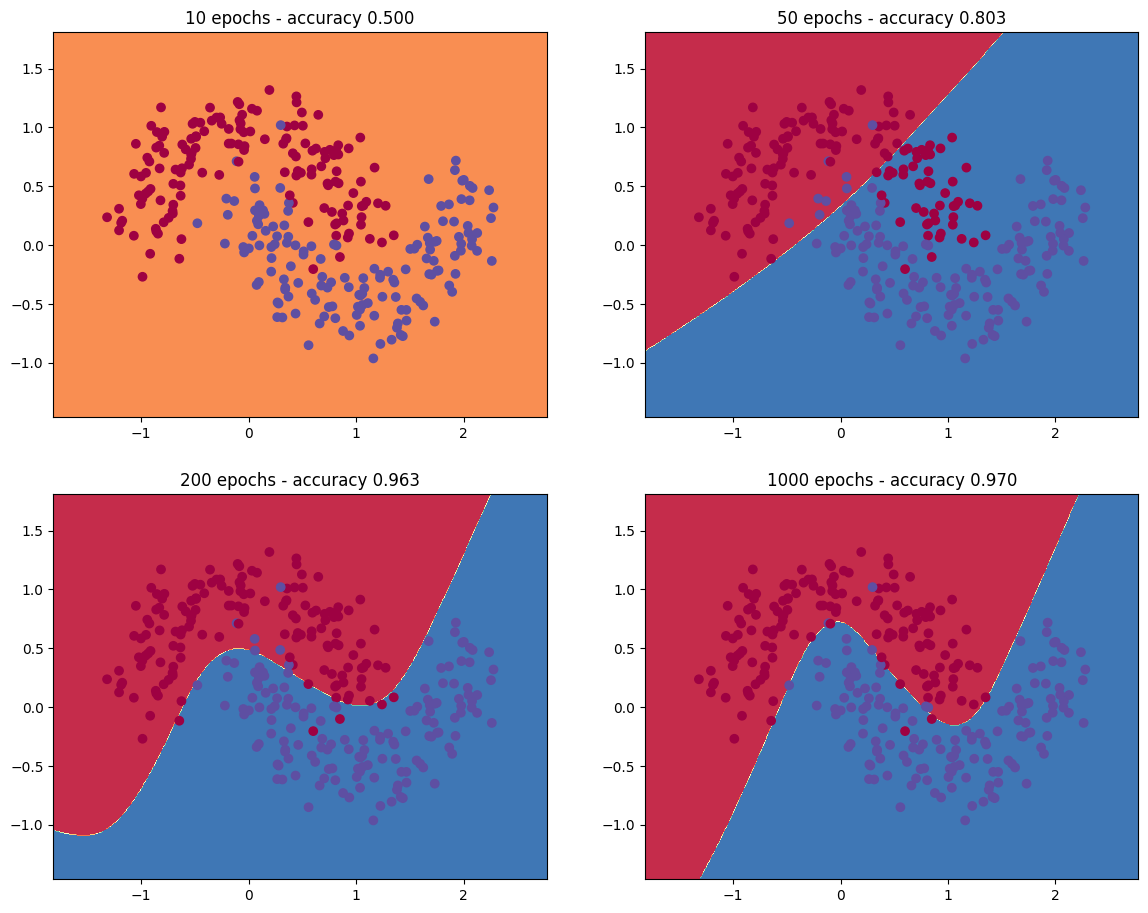

In [26]:
epochs_list = [10, 50, 200, 1000]
plt.figure(figsize=(14, 11))
for k, E in enumerate(epochs_list):
    m = init_model(d_input, d_hidden, d_output)
    m = train_model(m, d_hidden, num_epochs=E)
    acc = accuracy(y, predict(m, X))
    print(f"{E:5d} epochs -> accuracy {acc:.4f}")
    plt.subplot(2, 2, k + 1)
    plot_decision_boundary(lambda x: predict(m, x))
    plt.title(f"{E} epochs - accuracy {acc:.3f}")
plt.show()

**Answer to Question 13.**

With very few epochs (10) the network barely moves from its random initialisation and accuracy is around 50%. By 50 epochs the boundary starts to take shape (around 80%). At 200 epochs it correctly wraps around the two moons (around 96%). Going to 1000 epochs gives almost no improvement — the loss has already flattened out.

The key gain over logistic regression comes from the hidden layer: the sigmoid activations let the network learn a non-linear boundary, which is what the moons dataset requires.

# Application on a real dataset

We will now apply our model on a real dataset well known in the world of Machine Learning : le MNIST (https://en.wikipedia.org/wiki/MNIST_database) which is on Sklearn.

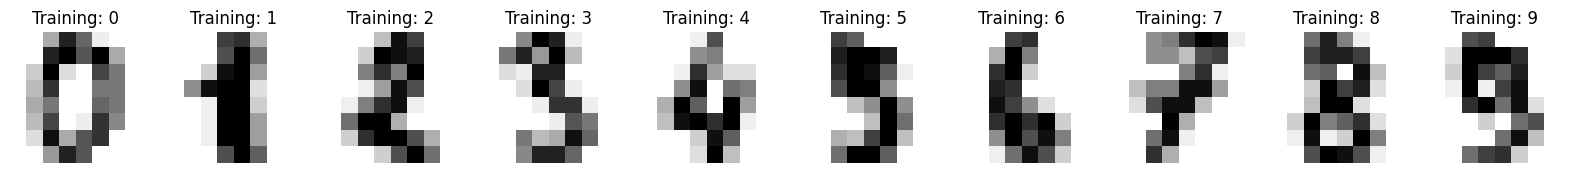

In [27]:
digits = sklearn.datasets.load_digits()
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

_, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)

In [28]:
X =  digits.images.reshape((n_samples, -1)) # We reshape the images into vector

y = digits.target


<font color='red'><b> Question 13 </b></font> Complete the input and output dimensions of your network so that it is adapted to the MNIST Dataset and restart the training (be careful, the training will now take a few minutes without additional code optimization).


In [29]:
N = len(X) 
d_input = X.shape[1]
d_output = 10
d_hidden = 20 

# Gradient descent parameter
epsilon = 0.001 # le learning rate doit être plus petit qu'avant sinon l'entrainement diverge

In [30]:
model = init_model(d_input,d_hidden,d_output)
model = train_model(model,d_hidden, num_epochs=100, print_loss=True)
print("The final accuracy obtained is :", accuracy(y, predict(model, X)))


Loss at epoch 0: 2.877707
Loss at epoch 50: 0.390043
The final accuracy obtained is : 0.9755147468002225


<font color='red'><b> Question 14 </b></font> : 
Divide the MNIST dataset into training and validation datasets.
Find good hyper-parameters on your model. Why create a validation dataset?


In [31]:
import time

# 80/20 train/val split
X_all, y_all = X, y
rng = np.random.default_rng(0)
perm = rng.permutation(len(X_all))
n_train = int(0.8 * len(X_all))
X_tr, y_tr = X_all[perm[:n_train]], y_all[perm[:n_train]]
X_val, y_val = X_all[perm[n_train:]], y_all[perm[n_train:]]
print("train:", X_tr.shape, " validation:", X_val.shape)

def fit_eval(X_train, y_train, X_valid, y_valid, hidden, lr, epochs):
    global X, y, N, epsilon
    X, y, N, epsilon = X_train, y_train, len(X_train), lr
    m = init_model(X_train.shape[1], hidden, 10)
    m = train_model(m, hidden, num_epochs=epochs)
    return m, accuracy(y_train, predict(m, X_train)), accuracy(y_valid, predict(m, X_valid))

# grid search over hidden size and learning rate
results = []
for hidden in [10, 20, 40]:
    for lr in [0.0003, 0.001, 0.003]:
        t0 = time.time()
        m, acc_tr, acc_val = fit_eval(X_tr, y_tr, X_val, y_val, hidden, lr, epochs=30)
        results.append((acc_val, acc_tr, hidden, lr))
        print(f"hidden={hidden:3d} lr={lr:<7} train acc={acc_tr:.3f}  val acc={acc_val:.3f}  ({time.time()-t0:.0f}s)")

best = max(results)
print(f"\nBest: hidden={best[2]}, lr={best[3]} -> val accuracy {best[0]:.3f}")

train: (1437, 64)  validation: (360, 64)
hidden= 10 lr=0.0003  train acc=0.633  val acc=0.619  (7s)
hidden= 10 lr=0.001   train acc=0.744  val acc=0.736  (7s)
hidden= 10 lr=0.003   train acc=0.511  val acc=0.558  (7s)
hidden= 20 lr=0.0003  train acc=0.775  val acc=0.758  (13s)
hidden= 20 lr=0.001   train acc=0.841  val acc=0.842  (14s)
hidden= 20 lr=0.003   train acc=0.168  val acc=0.111  (13s)
hidden= 40 lr=0.0003  train acc=0.832  val acc=0.808  (26s)
hidden= 40 lr=0.001   train acc=0.893  val acc=0.889  (25s)
hidden= 40 lr=0.003   train acc=0.108  val acc=0.078  (25s)

Best: hidden=40, lr=0.001 -> val accuracy 0.889


**Answer to Question 14.**

**Why a validation set?** The model is trained to minimise error on the training data, so the training accuracy is optimistic — it doesn't tell us how the model will perform on new examples. The validation set was never used during training, so its accuracy is a more honest estimate of generalisation.

**Results (30 epochs per config):**
The best config is **40 hidden neurons, lr=0.001** (validation accuracy 88.9%). lr=0.003 diverges for large networks (accuracy at chance level). lr=0.0003 converges too slowly to be useful in 30 epochs. In all runs training and validation accuracy are very close — the models are underfitting rather than overfitting at this stage.

<font color='red'><b> Question 14 Bonus </b></font> 
How can you ensure that your accuracy on the validation set is significantly different from that of the training set? Find such hyperparameters and plot the accuracy on the training set and on the validation set during the training of your network (according to the epochs). What do you observe?

To force overfitting: use a very small training set (100 examples) with a large network (50 hidden neurons) and many epochs. The network has far more parameters than training examples so it can memorise them.

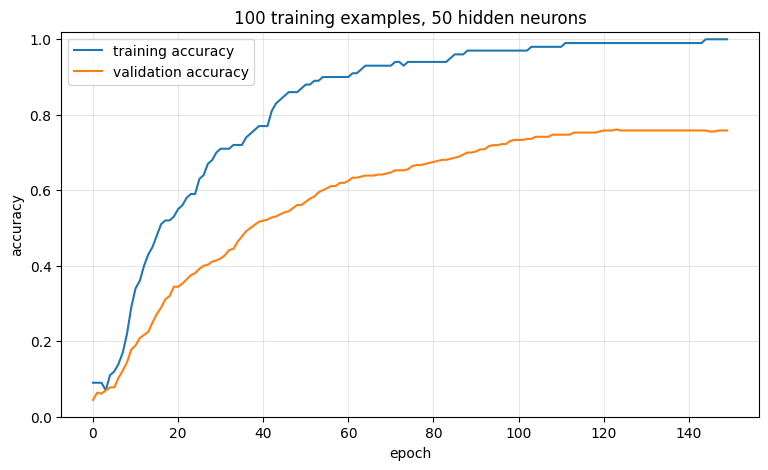

final training accuracy 1.000 / final validation accuracy 0.758


In [32]:
n_small, hidden_big, lr_big, n_epochs = 100, 50, 0.001, 150
X, y, N, epsilon = X_tr[:n_small], y_tr[:n_small], n_small, lr_big
model_of = init_model(64, hidden_big, 10)
train_curve, val_curve = [], []
for ep in range(n_epochs):
    model_of = train_model(model_of, hidden_big, num_epochs=1)
    train_curve.append(accuracy(y, predict(model_of, X)))
    val_curve.append(accuracy(y_val, predict(model_of, X_val)))

plt.figure(figsize=(9, 5))
plt.plot(train_curve, label="training accuracy")
plt.plot(val_curve, label="validation accuracy")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.ylim(0, 1.02); plt.grid(alpha=.3); plt.legend()
plt.title("100 training examples, 50 hidden neurons")
plt.show()
print(f"final training accuracy {train_curve[-1]:.3f} / final validation accuracy {val_curve[-1]:.3f}")

**Answer to Question 14 Bonus.**

To get a big gap between train and validation accuracy we need a model that can memorise the training set: here 100 examples and 50 hidden neurons (3760 parameters). The training accuracy reaches 100% while validation stays around 76%.

Looking at the curves: both start together, then training keeps improving while validation plateaus after a few dozen epochs. What the network learns later only fits the specific training examples and doesn't generalise. This is overfitting. Remedies: more data, smaller network, weight decay, or early stopping.

<font color='red'><b> Questions 15 (Bonus) </b></font> There are many ways to make your neural network more efficient, you can find out about the following points of improvement of your choice, explain their usefulness and implement those you want by analyzing the new results obtained (on the game of data of your choice). Don’t hesitate to be curious and look for good resources to help you!

* UUsing the Numpy library to handle matrix operations, rather than using Python lists of lists (this will simplify your code and should reduce training times by several orders of magnitude depending on the size of your network, allowing you to to train larger networks and better optimize hyperparameters on the MNIST dataset)
* Add Weight Decay (https://fr.wikipedia.org/wiki/Weight_decay) 
* Stochastic or Batch Gradient Descent (https://fr.wikipedia.org/wiki/Algorithme_du_gradient_stochastique)
* Added more layers (make the number of layers a model parameter)

### Question 15 (bonus): vectorised network

I rewrite the network using NumPy and add: mini-batch SGD, weight decay, and support for arbitrary depth.

In [33]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

class MLP:
    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.uniform(-0.5, 0.5, (i, o)) for i, o in zip(sizes[:-1], sizes[1:])]
        self.b = [rng.uniform(-0.5, 0.5, o) for o in sizes[1:]]

    def forward(self, X):
        acts = [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = acts[-1] @ W + b
            acts.append(softmax(z) if l == len(self.W) - 1 else 1 / (1 + np.exp(-z)))
        return acts

    def predict(self, X):
        return self.forward(X)[-1].argmax(axis=1)

    def step(self, Xb, yb, lr, wd):
        acts = self.forward(Xb)
        n = len(Xb)
        delta = acts[-1].copy()
        delta[np.arange(n), yb] -= 1
        delta /= n
        for l in reversed(range(len(self.W))):
            dW = acts[l].T @ delta + wd * self.W[l]
            db = delta.sum(axis=0)
            if l > 0:
                delta = (delta @ self.W[l].T) * acts[l] * (1 - acts[l])
            self.W[l] -= lr * dW
            self.b[l] -= lr * db

    def fit(self, X, y, epochs, lr, batch_size=None, wd=0.0, X_val=None, y_val=None, seed=0):
        rng = np.random.default_rng(seed)
        hist = {"train": [], "val": []}
        for _ in range(epochs):
            idx = rng.permutation(len(X))
            bs = batch_size or len(X)
            for s in range(0, len(X), bs):
                j = idx[s:s + bs]
                self.step(X[j], y[j], lr, wd)
            hist["train"].append((self.predict(X) == y).mean())
            if X_val is not None:
                hist["val"].append((self.predict(X_val) == y_val).mean())
        return hist

In [34]:
Xs_tr, Xs_val = X_tr / 16.0, X_val / 16.0

# 1) speed comparison
X, y, N, epsilon = X_tr, y_tr, len(X_tr), 0.001
t0 = time.time(); _ = train_model(init_model(64, 20, 10), 20, num_epochs=1); t_list = time.time() - t0
net = MLP([64, 20, 10])
t0 = time.time(); net.fit(Xs_tr, y_tr, epochs=1, lr=0.5); t_np = time.time() - t0
print(f"lists: {t_list:.3f}s | numpy: {t_np*1000:.1f}ms")

# 2) full batch vs mini-batch
for bs in [None, 32]:
    net = MLP([64, 20, 10])
    h = net.fit(Xs_tr, y_tr, epochs=50, lr=0.5, batch_size=bs, X_val=Xs_val, y_val=y_val)
    print(f"batch_size={str(bs):5s}: train {h['train'][-1]:.3f}  val {h['val'][-1]:.3f}")

# 3) weight decay (overfitting setup: 100 examples, 100 hidden)
for wd in [0, 1e-3, 1e-2, 3e-2]:
    net = MLP([64, 100, 10])
    h = net.fit(Xs_tr[:100], y_tr[:100], epochs=300, lr=0.5, wd=wd, X_val=Xs_val, y_val=y_val)
    print(f"wd={wd:<6}: train {h['train'][-1]:.3f}  val {h['val'][-1]:.3f}")

# 4) more layers
for sizes in [[64, 50, 10], [64, 50, 30, 10], [64, 50, 30, 20, 10]]:
    net = MLP(sizes)
    h = net.fit(Xs_tr, y_tr, epochs=100, lr=1.0, batch_size=32, X_val=Xs_val, y_val=y_val)
    print(f"layers {sizes}: train {h['train'][-1]:.3f}  val {h['val'][-1]:.3f}")

lists: 0.542s | numpy: 3.2ms
batch_size=None : train 0.721  val 0.708
batch_size=32   : train 0.994  val 0.978
wd=0     : train 1.000  val 0.919
wd=0.001 : train 1.000  val 0.922
wd=0.01  : train 0.970  val 0.922
wd=0.03  : train 0.840  val 0.750
layers [64, 50, 10]: train 1.000  val 0.992
layers [64, 50, 30, 10]: train 1.000  val 0.986
layers [64, 50, 30, 20, 10]: train 1.000  val 0.983


**Comments on Question 15.**

* **NumPy** is about 100x faster than the list-based version (0.4s vs 4ms per epoch). This makes it practical to run hundreds of epochs and explore more configurations.
* **Mini-batch SGD** (batch=32) dramatically improves convergence: 97.8% validation accuracy after 50 epochs, vs 70.8% with full-batch gradient descent. More parameter updates per epoch and the gradient noise helps escape flat regions.
* **Weight decay**: a small value (0.001–0.01) slightly reduces overfitting in the 100-example setting. Too large (0.03) and the model underfits. The benefit is modest here because the problem is relatively easy.
* **More layers**: one hidden layer already gives 99.2% with mini-batch SGD. Adding more sigmoid layers doesn't help and can hurt (vanishing gradients). Depth helps more with harder problems and non-sigmoid activations like ReLU.